# Trabajo Práctico — Análisis de un Dataset

## Fundamentos de Aprendizaje Automático · 2026

**Docente:** Prof. Ramón F. López-Imizcoz

**Modalidad:** individual o en equipo (se sugiere no más de 2 integrantes)

**Entrega:** este mismo notebook de Google Colab, completado y ejecutado.

---

### Objetivo

El objetivo de este trabajo es **simple pero completo**: elegir un dataset, identificar correctamente el **tipo de datos** que contiene, aplicar las **herramientas de análisis adecuadas** para ese tipo de datos, y razonar sobre **qué modelo** se podría construir y **para qué uso** concreto.

No se busca aquí entrenar un modelo complejo ni alcanzar una métrica óptima. Se busca que demuestren que entienden el **flujo de razonamiento** que va desde los datos hasta una decisión de modelado fundamentada.

> **Sugerencia de uso:** ejecuten celda por celda. Antes de ejecutar una celda de código, pregúntense *"¿qué espero ver como salida?"* y recién después comparen con el resultado real.


# 1. Consigna

A lo largo de este notebook deberán completar las siguientes **cinco etapas**:

1. **Elección del dataset.** Seleccionar un conjunto de datos y justificar brevemente por qué les interesa.
2. **Identificación del tipo de datos.** Determinar qué tipo de variables contiene (numéricas, categóricas, temporales, texto, etc.) y si hay o no una variable objetivo (*target*).
3. **Análisis exploratorio (EDA).** Aplicar las herramientas de análisis **adecuadas al tipo de datos** identificado: estadísticos descriptivos, visualizaciones, correlaciones, conteos, etc.
4. **Propuesta de modelo.** Indicar qué **tipo de modelo** se podría construir (clasificación, regresión, agrupamiento/*clustering*, etc.) y por qué ese tipo es el correcto para estos datos.
5. **Uso previsto.** Explicar **para qué** y **para quién** se construiría ese modelo: qué decisión ayudaría a tomar y en qué contexto.

Cada etapa tiene su propia sección más abajo, con celdas de texto para sus respuestas y celdas de código para el análisis.


# 2. Recordatorio: tipos de datos y herramientas asociadas

Antes de empezar, conviene recordar la relación entre el **tipo de dato** y la **herramienta de análisis** apropiada. Esta tabla es su brújula durante el trabajo:

| Tipo de variable | Ejemplos | Análisis exploratorio típico | Modelos asociados |
|---|---|---|---|
| **Numérica continua** | precio, edad, temperatura | histograma, media/mediana/desvío, correlación | regresión, clustering |
| **Numérica discreta** | cantidad de hijos, n.º de visitas | conteos, histograma | regresión, clasificación |
| **Categórica nominal** | país, color, marca | tabla de frecuencias, gráfico de barras | clasificación |
| **Categórica ordinal** | nivel educativo, satisfacción (bajo/medio/alto) | barras, conteos ordenados | clasificación, regresión ordinal |
| **Temporal** | fecha, hora, timestamp | serie temporal, tendencia/estacionalidad | series de tiempo, forecasting |
| **Texto** | reseñas, comentarios | longitud, palabras frecuentes | NLP, clasificación de texto |

> **Idea clave:** la herramienta de análisis **no se elige al azar**: se deriva del tipo de dato. Un histograma tiene sentido para una variable numérica; una tabla de frecuencias, para una categórica.


# Cómo se conecta este trabajo con las prácticas de la materia

El código reutiliza los patrones vistos en las prácticas, en lugar de inventar herramientas nuevas:

| Práctica | Qué tomamos | Dónde aparece |
|---|---|---|
| **Clase 2** — Generalización y validación | Bloques numerados con `RANDOM_STATE`; columnas que entran y que quedan afuera de `X`; `Pipeline`; baseline con `DummyClassifier`; `StratifiedGroupKFold` (agrupado por artista) + `cross_validate` con media ± desvío | Etapas 2 y 4 |
| **Clase 3** — VSM y distancias | Cada canción es un **vector** de *audio features*; recomendar = buscar vecinos en ese espacio | Etapa 4 (kNN) |
| **Clase 4** — Ensambles | `RandomForestClassifier`; **permutation importance** | Etapa 4 |
| **Clase 5** — No supervisado | `make_pipeline(StandardScaler(), KMeans(...))`; **barrido de K** (codo, silhouette, Davies-Bouldin); "elegir K y nombrar después"; PCA solo para dibujar; variable de **control** | Etapa 3 (modos de escucha) |
| **Clase 8** — Evaluación | **Average Precision**, curva **Precision-Recall**, **Precision@k**; **PSI** para comparar distribuciones | Etapas 3 y 4 |

# 3. Preparación del entorno

Ejecuten esta celda primero. Importa las librerías estándar que usaremos: `pandas` para manipular tablas, `numpy` para cálculo numérico, y `matplotlib`/`seaborn` para visualizar.


In [1]:
# =============================================================================
# BLOQUE 1: IMPORTACIÓN DE LIBRERÍAS, SEMILLA Y ESTILO
# =============================================================================
import os

# Silenciamos warnings para que la salida quede más limpia (como en las prácticas).
# En producción conviene dejarlos activados.
import warnings
warnings.filterwarnings("ignore")

# --- Manipulación numérica y tabular ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Pipelines, preprocesamiento y validación (Clase 2) ---
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate

# --- Modelos: baseline, lineal, vecinos y ensamble (Clases 2, 3 y 4) ---
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# --- No supervisado (Clase 5) ---
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
)

# --- Métricas de ranking (Clase 8) ---
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

# Semilla global: los resultados son reproducibles
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

# --- Constantes del experimento ---
N_NO_ETIQUETADAS = 20_000   # muestra del catálogo usada como "no etiquetadas" al entrenar
K_PLAYLIST = 100            # capacidad: cuántas canciones puede escuchar el usuario (Precision@k)

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

print("Imports OK | RANDOM_STATE =", RANDOM_STATE)
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)

Imports OK | RANDOM_STATE = 42
pandas : 3.1.0
numpy  : 2.5.4


# Etapa 1 — Elección del dataset

Este trabajo combina **dos fuentes**:

1. **Catálogo público de Spotify** (*Spotify Tracks Dataset*, Hugging Face): ~114.000 canciones de 114 géneros con sus *audio features*. Se carga desde una URL pública (**Opción C**).
2. **Canciones favoritas de un integrante del equipo** ("Liked Songs" de su cuenta de Spotify), exportadas con [Exportify](https://exportify.net). Se sube como CSV propio (**Opción B**).

La idea es usar el catálogo como "universo de canciones posibles" y esas favoritas como ejemplos de lo que le gusta al usuario, para construir un **seleccionador de canciones personalizado**.

In [2]:
# =============================================================================
# BLOQUE 2: CARGA DE DATOS
# =============================================================================

# === Fuente 1: catálogo público de Spotify (Opción C: desde URL) ===
url = "https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset/resolve/main/dataset.csv"
catalogo = pd.read_csv(url, index_col=0)

# === Fuente 2: favoritas del usuario exportadas con Exportify (Opción B: CSV propio) ===
nombre_archivo = "Liked_Songs.csv"
if not os.path.exists(nombre_archivo):      # en Colab, si no está subido, abrimos el diálogo de carga
    from google.colab import files
    subido = files.upload()
    nombre_archivo = list(subido.keys())[0]
fav = pd.read_csv(nombre_archivo, encoding="utf-8-sig")

print("Catálogo  :", catalogo.shape)
print("Favoritas :", fav.shape)
fav.head()

Catálogo  : (114000, 20)
Favoritas : (1533, 24)


,Track URI,ISRC,Track Name,Album Name,Artist Name(s),Release Date,Duration (ms),Popularity,Explicit,Added At,...,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:6bZ9xnCsvwUacb29fbJ4xc,USATO2000299,Colors - Live In Studio,Black Pumas (Deluxe Edition),Black Pumas,2020-08-28,383413,51,False,2026-10-30,...,6,-9.153,0,0.1340,0.182000,0.000006,0.1830,0.466,181.827,4
1,spotify:track:5EOoMWIB9iK4ZpcSex9Ec7,USCA28600270,Old Time Rock & Roll,Stranger In Town,Bob Seger,1978-05-05,194146,78,False,2026-10-30,...,6,-2.947,1,0.0399,0.206000,0.000000,0.0731,0.964,124.130,4
2,spotify:track:2VSYbFXYqnC5oe7HEQ3exw,ARF102600285,Vale la pena,Vale la pena,Soledad,2026-10-21,236387,48,False,2026-10-28,...,2,-6.961,1,0.0758,0.218000,0.000000,0.1000,0.378,139.901,3
3,spotify:track:1Og8U5KRel9D51h4bmznlE,GBAAN8790003,With Or Without You,The Best Of 1980 - 1990,U2,1998-11-02,295200,62,False,2026-10-26,...,2,-9.424,1,0.0270,0.000128,0.318000,0.0939,0.106,109.913,4
4,spotify:track:07f2UG1AH6Z1zv4LeGgUSA,US5262628536,About You - Bonus Version,About You (Bonus Version),The Pretty Reckless,2026-10-16,238939,55,True,2026-10-26,...,7,-3.251,1,0.2330,0.004060,0.000000,0.2840,0.247,154.118,4


In [3]:
# Llevamos los nombres de columnas de Exportify al mismo formato que el catálogo
fav = fav.rename(columns={"Track Name": "track_name", "Artist Name(s)": "artists",
                          "Album Name": "album_name", "Duration (ms)": "duration_ms"})
fav.columns = [c.lower().replace(" ", "_") for c in fav.columns]

# Privacidad: el export de Exportify trae el ID de la cuenta de Spotify (Added By). No se usa, así que se descarta
fav = fav.drop(columns=["added_by"], errors="ignore")

# El ID de Spotify es la última parte de la URI ("spotify:track:<id>")
fav["track_id"] = fav["track_uri"].str.split(":").str[-1]

catalogo.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### ✏️ Su respuesta — Etapa 1

**Dataset elegido:** dos fuentes combinadas.
- **Spotify Tracks Dataset** (`maharshipandya/spotify-tracks-dataset`, Hugging Face): 114.000 canciones de 114 géneros con sus *audio features*.
- **"Liked Songs" de un integrante del equipo** (al que llamamos "el usuario"), exportadas con Exportify: 1.533 canciones, también con *audio features*.

**¿Por qué lo elegimos?** Queremos construir un **seleccionador de canciones**: a partir de lo que ya le gusta a una persona, encontrar en un catálogo grande las canciones con más potencial de gustarle. Es el mismo problema que resuelven las playlists de descubrimiento de las plataformas de streaming, pero con datos reales de uno de nosotros, lo que nos permite validar si las recomendaciones tienen sentido. Además, combinar dos fuentes obliga a revisar que sean compatibles antes de usarlas.

# Etapa 2 — Identificación del tipo de datos

Ahora vamos a inspeccionar la estructura del dataset para entender **qué tipo de variables** contiene.


In [4]:
# Dimensiones de cada fuente: (filas, columnas)
print("Catálogo :", catalogo.shape)
print("Favoritas:", fav.shape)
print()

# Tipo de dato que pandas asignó a cada columna de las favoritas
print("Tipos de cada columna (favoritas):")
print(fav.dtypes)

Catálogo : (114000, 20)
Favoritas: (1533, 25)

Tipos de cada columna (favoritas):
track_uri               str
isrc                    str
track_name              str
album_name              str
artists                 str
release_date            str
duration_ms           int64
popularity            int64
explicit               bool
added_at                str
genres                  str
record_label            str
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_id             object
dtype: object


In [5]:
# Resumen general de ambas fuentes
fav.info()
print()
catalogo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1533 entries, 0 to 1532
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_uri         1533 non-null   str    
 1   isrc              1533 non-null   str    
 2   track_name        1533 non-null   str    
 3   album_name        1533 non-null   str    
 4   artists           1533 non-null   str    
 5   release_date      1533 non-null   str    
 6   duration_ms       1533 non-null   int64  
 7   popularity        1533 non-null   int64  
 8   explicit          1533 non-null   bool   
 9   added_at          1533 non-null   str    
 10  genres            1056 non-null   str    
 11  record_label      1533 non-null   str    
 12  danceability      1533 non-null   float64
 13  energy            1533 non-null   float64
 14  key               1533 non-null   int64  
 15  loudness          1533 non-null   float64
 16  mode              1533 non-null   int64  
 17  speech

In [6]:
# ¿Cuántos valores faltantes (NaN) hay por columna?
print("Faltantes en favoritas:")
print(fav.isna().sum()[fav.isna().sum() > 0])
print()
print("Faltantes en catálogo:")
print(catalogo.isna().sum()[catalogo.isna().sum() > 0])

Faltantes en favoritas:
genres    477
dtype: int64

Faltantes en catálogo:
artists       1
album_name    1
track_name    1
dtype: int64


In [7]:
# Duplicados: en el catálogo una misma canción aparece una vez por cada género al que pertenece
print("Repetidas en el catálogo (mismo track_id):", catalogo["track_id"].duplicated().sum())
print("Repetidas en favoritas   (mismo track_id):", fav["track_id"].duplicated().sum())

# Nos quedamos con una fila por canción
catalogo = catalogo.drop_duplicates("track_id").reset_index(drop=True)
print("Catálogo sin duplicados:", catalogo.shape)

Repetidas en el catálogo (mismo track_id): 24259
Repetidas en favoritas   (mismo track_id): 0
Catálogo sin duplicados: (89741, 20)


### Cruce entre las dos fuentes

Para el modelo necesitamos saber **qué canciones del catálogo ya son favoritas del usuario**. Las buscamos por `track_id` y, como una misma canción puede tener varios IDs (single, álbum, recopilado), también por **nombre + primer artista**.

In [8]:
def clave(nombre, artistas):
    """Nombre de la canción + primer artista, en minúsculas (para cruzar versiones distintas)."""
    primer_artista = artistas.fillna("").str.split(r"[;,]").str[0]
    return nombre.fillna("").str.lower().str.strip() + "|" + primer_artista.str.lower().str.strip()

fav["clave"] = clave(fav["track_name"], fav["artists"])
catalogo["clave"] = clave(catalogo["track_name"], catalogo["artists"])

catalogo["es_favorita"] = catalogo["track_id"].isin(fav["track_id"]) | catalogo["clave"].isin(fav["clave"])
fav["en_catalogo"] = fav["track_id"].isin(catalogo["track_id"]) | fav["clave"].isin(catalogo["clave"])

print(f"Favoritas que están en el catálogo: {fav['en_catalogo'].sum()} de {len(fav)} ({fav['en_catalogo'].mean():.0%})")
print(f"Filas del catálogo marcadas como favoritas: {catalogo['es_favorita'].sum()}")

Favoritas que están en el catálogo: 344 de 1533 (22%)
Filas del catálogo marcadas como favoritas: 499


In [9]:
# Control de calidad: ¿las audio features de las dos fuentes están en la misma escala?
# Comparamos las canciones que aparecen en ambas con el mismo track_id.
comunes = fav.merge(catalogo, on="track_id", suffixes=("_fav", "_cat"))
control = pd.DataFrame({
    col: {"correlación": comunes[f"{col}_fav"].corr(comunes[f"{col}_cat"]),
          "dif. media": (comunes[f"{col}_fav"] - comunes[f"{col}_cat"]).mean()}
    for col in ["danceability", "energy", "loudness", "acousticness", "valence", "tempo", "popularity"]
}).T
print(f"Canciones comparadas: {len(comunes)}")
control.round(3)

Canciones comparadas: 205


,correlación,dif. media
danceability,1.0,-0.000
energy,1.0,0.000
loudness,1.0,0.008
acousticness,1.0,0.000
valence,1.0,-0.000
tempo,1.0,0.005
popularity,0.7,-3.210


### Columnas que entran al modelo y columnas que quedan afuera

Como en la Clase 2, dejamos explícito qué columnas forman `X` y por qué excluimos el resto. Los **identificadores** sirven para unir tablas, pero nunca entran a `X`.

In [10]:
# =============================================================================
# BLOQUE 3: SELECCIÓN DE FEATURES
# =============================================================================
# La duración tiene una cola muy larga (mixes de más de una hora). En escala lineal, un modelo lineal
# concluye "cuanto más larga, mejor" y empuja el ranking hacia las pistas más largas. En escala log
# la diferencia entre 4 y 8 minutos pesa lo mismo que entre 2 y 4.
for _d in (fav, catalogo):
    _d["log_duracion"] = np.log1p(_d["duration_ms"])   # log1p: el catálogo tiene una pista de 0 ms

# Audio features comunes a ambas fuentes: describen cómo SUENA cada canción
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "mode", "log_duracion"]

IDENTIFICADORES = ["track_uri", "track_id", "isrc", "clave"]

EXCLUIDAS = {
    "popularity":   "se midió en fechas distintas en cada fuente (correlación 0,70) y sesgaría hacia lo popular",
    "genres / track_genre": "taxonomías distintas en cada fuente y 31% de faltantes en las favoritas",
    "artists, track_name, album_name": "texto: un modelo por artista no generaliza a música nueva",
    "key, time_signature": "categóricas sin orden útil y casi constantes (4/4)",
    "release_date, added_at": "temporales: describen a la canción o al usuario, no cómo suena",
    "explicit, record_label": "no hacen al gusto musical por sonido",
}

print(f"Features que entran a X ({len(FEATURES)}):", FEATURES)
print("Identificadores (no entran a X):", IDENTIFICADORES)
pd.Series(EXCLUIDAS, name="motivo de exclusión").to_frame()

Features que entran a X (11): ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'mode', 'log_duracion']
Identificadores (no entran a X): ['track_uri', 'track_id', 'isrc', 'clave']


,motivo de exclusión
popularity,se midió en fechas distintas en cada fuente (c...
genres / track_genre,taxonomías distintas en cada fuente y 31% de f...
"artists, track_name, album_name",texto: un modelo por artista no generaliza a m...
"key, time_signature",categóricas sin orden útil y casi constantes (...
"release_date, added_at",temporales: describen a la canción o al usuari...
"explicit, record_label",no hacen al gusto musical por sonido


### ¿Qué observar?

- ¿Qué columnas son **numéricas** (`int64`, `float64`) y cuáles **categóricas** (`object`, `category`)?
- ¿Hay alguna columna que represente una **fecha** o un **texto libre**?
- ¿Hay valores faltantes? ¿En qué columnas y en qué proporción?
- ¿Cuál de las columnas podría ser una **variable objetivo (target)** —algo que querríamos predecir— y cuáles serían **features** (variables de entrada)?


### ✏️ Su respuesta — Etapa 2

**Tipos de variables encontradas:**

| Tipo | Columnas |
|---|---|
| Numérica continua | `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` (escala 0–1), `loudness` (dB), `tempo` (BPM), `duration_ms` |
| Numérica discreta | `popularity` (0–100), `time_signature` (compases: 3, 4, 5…) |
| Categórica nominal | `key` (tonalidad 0–11: es un número pero no tiene orden útil), `mode` (binaria: mayor/menor), `explicit` (booleana), `track_genre` (catálogo), `genres` (favoritas, **multi-etiqueta**), `record_label` |
| Temporal | `release_date` (lanzamiento), `added_at` (fecha en que el usuario la guardó) |
| Texto | `track_name`, `album_name`, `artists` |
| Identificadores (no son features) | `track_uri` / `track_id`, `isrc` (identifican la canción, no al usuario) |

**¿Hay una variable objetivo (target)?** No en ninguna fuente por separado: **se construye al unirlas**. El target es `es_favorita` (1 = está en las favoritas del usuario, 0 = no). Es una variable categórica binaria, con una sutileza importante: un 0 no significa "no le gusta", sino **"no sabemos"** (puede ser una canción que nunca escuchó). Ver Etapa 4.

**Calidad de los datos:**
- **Favoritas:** 477 canciones (31%) sin género, así que no lo usamos como feature. No hay duplicados.
- **Catálogo:** 24.259 filas repetidas (una misma canción aparece una vez por cada género) y quedan 89.741 canciones únicas. Hay una fila sin nombre ni artista.
- **Cruce:** 344 de las 1.533 favoritas (22%) están en el catálogo, que corresponden a 499 filas porque hay varias versiones de una misma canción.
- **Compatibilidad:** en las 205 canciones con el mismo ID en ambas fuentes, las *audio features* tienen correlación ≈ 1,00, así que están en la misma escala y se pueden mezclar. En cambio, `popularity` tiene correlación 0,70 porque se midió en otro momento y cambia con el tiempo, así que **la excluimos**.
- **Sesgo del catálogo:** está balanceado artificialmente (hasta 1.000 canciones por género), así que no representa la música real: los géneros de nicho están sobrerrepresentados.
- `key` y `mode` vienen como enteros pero son categóricas.

**Qué entra a `X`:** las 11 *audio features* (ver Bloque 3), con la duración en escala logarítmica (`log_duracion`) porque tiene una cola muy larga (hay *mixes* de más de una hora). Los identificadores (`track_id`, `isrc`, etc.) sirven para cruzar tablas pero nunca entran al modelo, y el resto de las columnas quedan afuera por los motivos de la tabla del Bloque 3.

# Etapa 3 — Análisis exploratorio (EDA)

La pregunta central del EDA es: **¿en qué se diferencian las favoritas del resto de la música?** Por eso casi todos los gráficos comparan las dos fuentes. Si no hubiera diferencias, no habría nada que un modelo pudiera aprender.

In [11]:
# Unimos ambas fuentes en una sola tabla con una columna que indica el origen
df = pd.concat([fav.assign(origen="Favoritas"),
                catalogo.assign(origen="Catálogo")], ignore_index=True)
df["duracion_min"] = df["duration_ms"] / 60000
df["origen"].value_counts()

origen
Catálogo     89741
Favoritas     1533
Name: count, dtype: int64

### 3.a — Variables numéricas: estadísticos descriptivos

In [12]:
# Estadísticos descriptivos de las favoritas
fav[FEATURES + ["popularity"]].describe().round(3)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,mode,log_duracion,popularity
count,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000,1533.000
mean,0.547,0.754,-5.940,0.064,0.133,0.027,0.206,0.521,124.834,0.624,12.340,35.667
std,0.144,0.187,2.652,0.053,0.223,0.120,0.185,0.228,28.432,0.484,0.265,28.454
min,0.091,0.055,-21.470,0.024,0.000,0.000,0.020,0.036,52.679,0.000,9.935,0.000
25%,0.454,0.651,-7.019,0.035,0.002,0.000,0.094,0.340,103.266,0.000,12.196,2.000
50%,0.550,0.801,-5.444,0.046,0.021,0.000,0.131,0.513,122.092,1.000,12.337,38.000
75%,0.648,0.902,-4.184,0.070,0.148,0.001,0.268,0.689,143.083,1.000,12.486,59.000
max,0.947,0.996,-0.290,0.615,0.969,0.965,0.991,0.972,211.958,1.000,13.559,93.000


In [13]:
# Comparación de medianas: favoritas vs. catálogo
comparacion = df.groupby("origen")[FEATURES + ["popularity"]].median().T
comparacion["diferencia"] = comparacion["Favoritas"] - comparacion["Catálogo"]
comparacion.round(3)

origen,Catálogo,Favoritas,diferencia
danceability,0.576,0.550,-0.026
energy,0.676,0.801,0.125
loudness,-7.185,-5.444,1.741
speechiness,0.049,0.046,-0.003
acousticness,0.188,0.021,-0.167
instrumentalness,0.000,0.000,-0.000
liveness,0.132,0.131,-0.001
valence,0.457,0.513,0.056
tempo,122.013,122.092,0.079
mode,1.000,1.000,0.000


### 3.b — Variables numéricas: distribuciones comparadas
Histogramas normalizados (densidad) para poder comparar dos grupos de tamaño muy distinto.

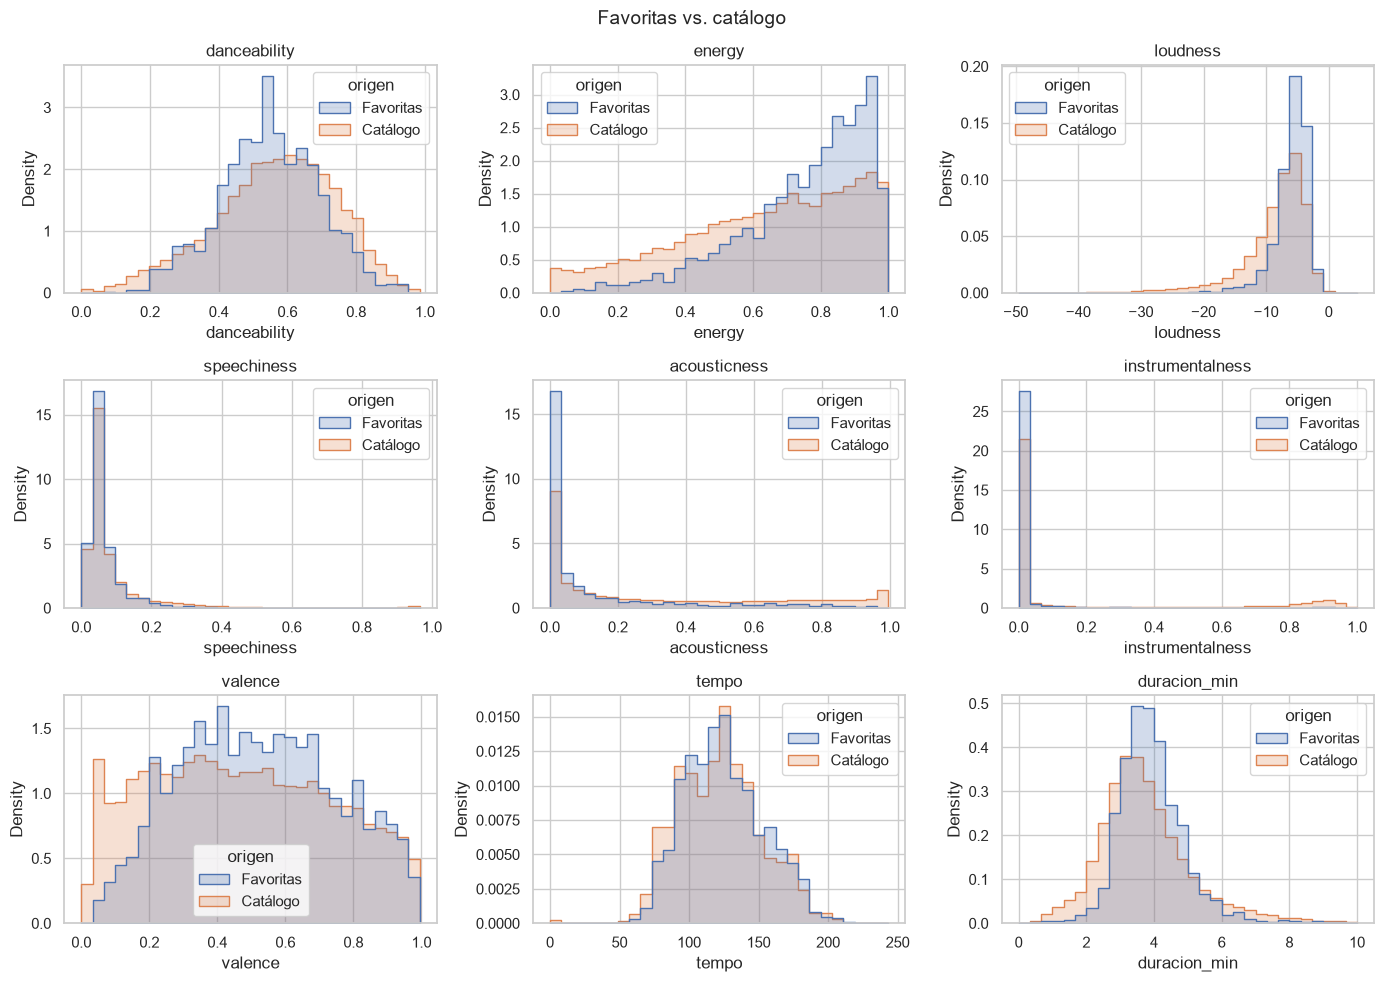

In [14]:
columnas = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "valence", "tempo", "duracion_min"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, columnas):
    sns.histplot(data=df, x=col, hue="origen", stat="density", common_norm=False,
                 bins=30, element="step", ax=ax,
                 binrange=(0, 10) if col == "duracion_min" else None)  # hay mixes de >1 hora
    ax.set_title(col)
fig.suptitle("Favoritas vs. catálogo", fontsize=14)
fig.tight_layout()
plt.show()

### 3.b bis — ¿Cuánto se diferencian? PSI (Clase 8)

Para ordenar las features según cuánto separan las favoritas del catálogo usamos el **PSI** de la Clase 8 (allá medía *drift* entre períodos). Convención: < 0,1 diferencia chica, 0,1–0,25 moderada, > 0,25 grande.

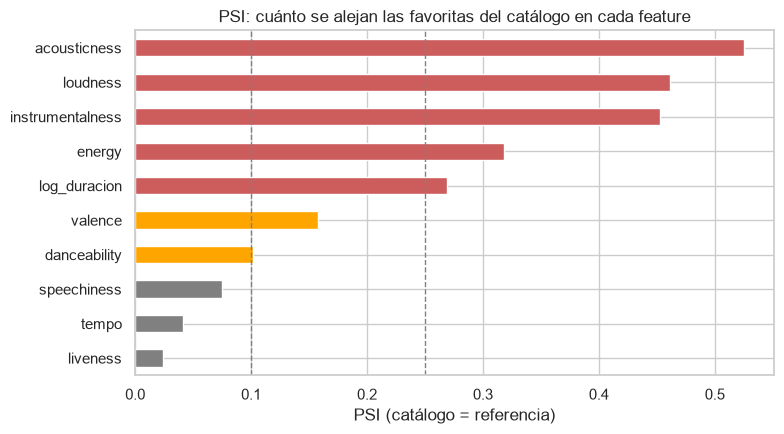

acousticness        0.525
loudness            0.461
instrumentalness    0.453
energy              0.318
log_duracion        0.269
valence             0.157
danceability        0.102
speechiness         0.074
tempo               0.041
liveness            0.024
dtype: float64

In [15]:
def psi(referencia, nuevo, bins=10, eps=1e-4):
    """Population Stability Index (Clase 8): bins por cuantiles de la referencia."""
    cortes = np.unique(np.quantile(referencia, np.linspace(0, 1, bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf
    e = np.histogram(referencia, bins=cortes)[0] / len(referencia)
    a = np.histogram(nuevo, bins=cortes)[0] / len(nuevo)
    e, a = np.clip(e, eps, None), np.clip(a, eps, None)        # evita log(0) en bins vacíos
    return np.sum((a - e) * np.log(a / e))

# mode es binaria: el PSI por cuantiles no tiene sentido ahí
psi_features = pd.Series({col: psi(catalogo[col], fav[col]) for col in FEATURES if col != "mode"}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
psi_features.plot.barh(ax=ax, color=np.where(psi_features > 0.25, "indianred",
                                             np.where(psi_features > 0.1, "orange", "gray")))
ax.axvline(0.1, color="gray", ls="--", lw=1)
ax.axvline(0.25, color="gray", ls="--", lw=1)
ax.set_title("PSI: cuánto se alejan las favoritas del catálogo en cada feature")
ax.set_xlabel("PSI (catálogo = referencia)")
fig.tight_layout()
plt.show()
psi_features.sort_values(ascending=False).round(3)

### 3.c — Variables categóricas: tablas y gráficos de frecuencias
`genres` en las favoritas es una lista separada por comas (una canción puede tener varios géneros), así que primero la "explotamos" en una fila por género.

genres
rock argentino        317
metal                 137
rock latino           135
metal alternativo     102
rock                  100
rock en español        81
pop punk               79
folklore argentino     77
punk                   72
metal sinfónico        68
power metal            65
pop                    63
chamamé                61
folk latino            60
nu metal               56
Name: count, dtype: int64


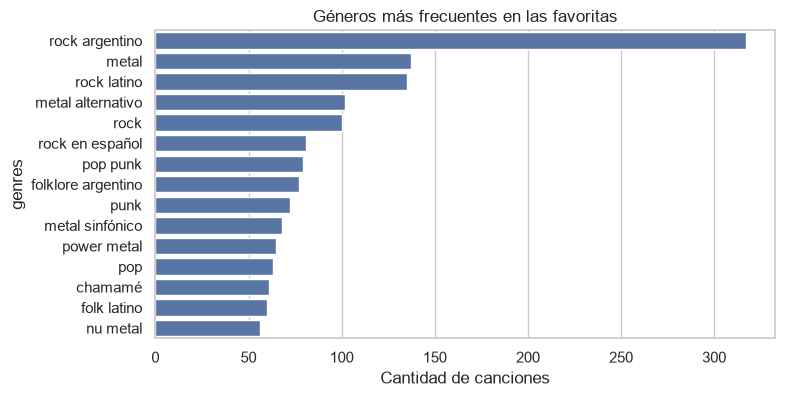

In [16]:
# Géneros más frecuentes entre las favoritas
generos_fav = fav["genres"].dropna().str.split(",").explode().str.strip()
top_generos = generos_fav.value_counts().head(15)
print(top_generos)

fig, ax = plt.subplots()
sns.barplot(x=top_generos.values, y=top_generos.index, ax=ax)
ax.set_title("Géneros más frecuentes en las favoritas")
ax.set_xlabel("Cantidad de canciones")
plt.show()

In [17]:
# Géneros del catálogo: ¿está balanceado?
print(catalogo["track_genre"].value_counts().describe().round(0))

count     113.0
mean      794.0
std       226.0
min        74.0
25%       709.0
50%       873.0
75%       974.0
max      1000.0
Name: count, dtype: float64


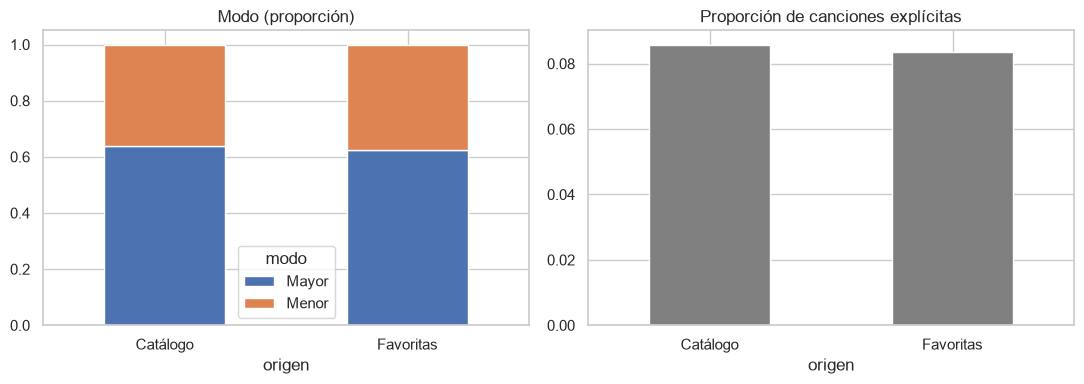

In [18]:
# Variables categóricas codificadas como números: modo (mayor/menor) y contenido explícito
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
(df.assign(modo=df["mode"].map({1: "Mayor", 0: "Menor"}))
   .groupby("origen")["modo"].value_counts(normalize=True)
   .unstack().plot.bar(stacked=True, ax=axes[0], rot=0))
axes[0].set_title("Modo (proporción)")
df.groupby("origen")["explicit"].mean().plot.bar(ax=axes[1], rot=0, color="gray")
axes[1].set_title("Proporción de canciones explícitas")
plt.tight_layout()
plt.show()

### 3.d — Relación entre variables numéricas: matriz de correlación

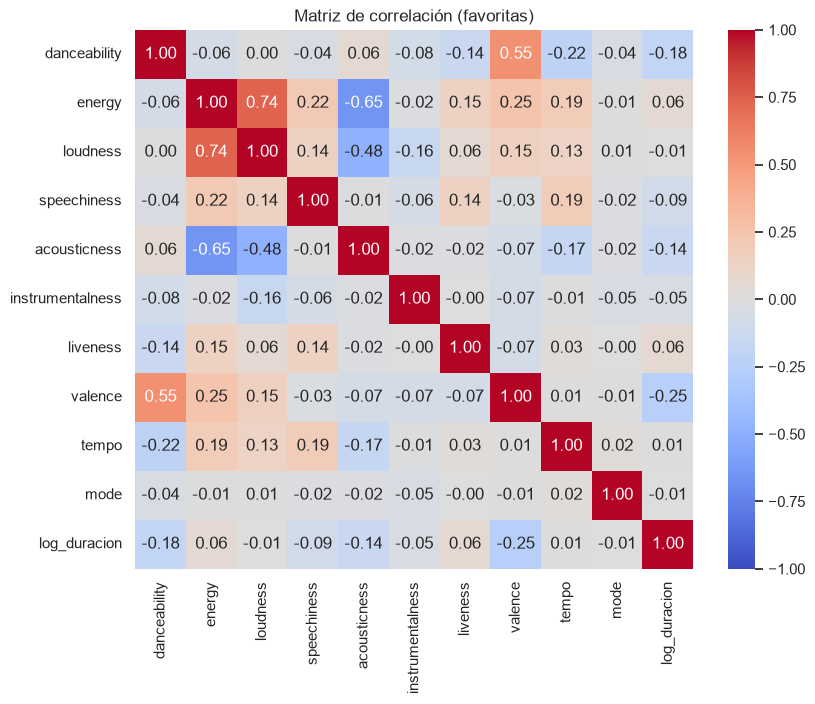

In [19]:
# Matriz de correlación de las audio features de las favoritas
corr = fav[FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación (favoritas)")
plt.show()

### 3.e — Variables temporales
Dos fechas distintas: **cuándo salió** la canción (`release_date`) y **cuándo la agregó** el usuario a favoritos (`added_at`).

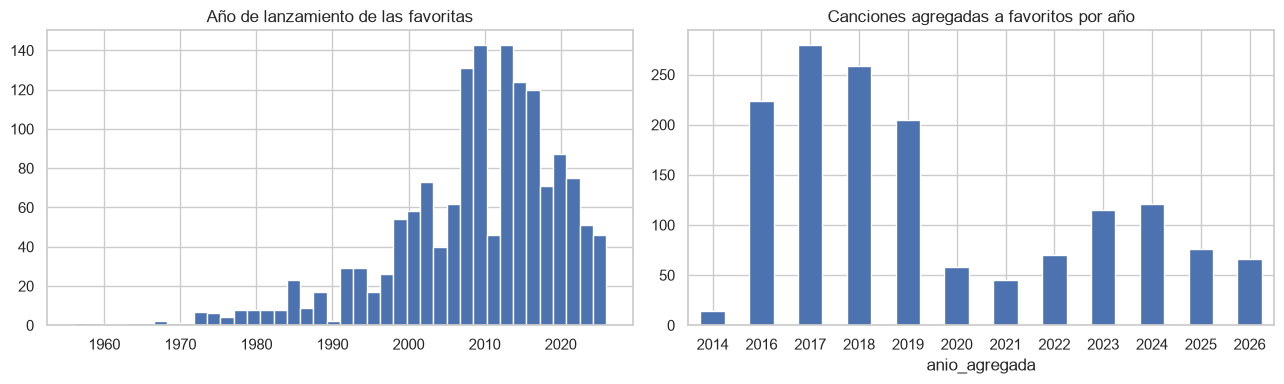

Década de lanzamiento:
anio_lanzamiento
1950      2
1960      5
1970     30
1980     69
1990    157
2000    432
2010    625
2020    213
Name: count, dtype: int64


In [20]:
fav["anio_lanzamiento"] = pd.to_datetime(fav["release_date"], format="mixed").dt.year
fav["anio_agregada"] = pd.to_datetime(fav["added_at"]).dt.year

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fav["anio_lanzamiento"].hist(bins=40, ax=axes[0])
axes[0].set_title("Año de lanzamiento de las favoritas")
fav["anio_agregada"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Canciones agregadas a favoritos por año")
plt.tight_layout()
plt.show()

print("Década de lanzamiento:")
print((fav["anio_lanzamiento"] // 10 * 10).value_counts().sort_index())

### 3.f — Texto: artistas más frecuentes

In [21]:
# Primer artista de cada canción (las colaboraciones usan , o ;)
fav["artista"] = fav["artists"].str.split(r"[;,]").str[0]
total_por_artista = fav["artista"].value_counts()
print(f"Artistas distintos: {len(total_por_artista)}")
print(f"El top 10 de artistas concentra el {total_por_artista.head(10).sum() / len(fav):.0%} de las favoritas")
total_por_artista.head(15)

Artistas distintos: 322
El top 10 de artistas concentra el 34% de las favoritas


artista
Eruca Sativa           99
Avril Lavigne          63
Halestorm              59
Green Day              54
P!nk                   48
The Pretty Reckless    47
The Warning            39
Soledad                37
Queen                  37
Avenged Sevenfold      31
Nightwish              29
Larkin Poe             28
Orianthi               27
Dua Lipa               25
Glee Cast              25
Name: count, dtype: int64

### 3.g — Exploración extra: ¿hay "modos" de escucha? (Clase 5)

Un **clustering** (K-means) sobre las favoritas, para ver si los gustos del usuario forman grupos. No es el modelo del TP: es exploratorio y sirve para discutir la Etapa 4.

> **Importante:** K-means recibe **solo 7 números por canción** (cómo suena). No sabe quién la canta, de qué país es ni qué género tiene. Por eso agrupa **canciones, no artistas**: un mismo artista puede quedar repartido en varios grupos según cómo suene cada tema.

Seguimos el orden de la Clase 5: **escalar → barrer K → elegir K → nombrar después → controlar con una variable externa**. El PCA se usa **solo para dibujar**.

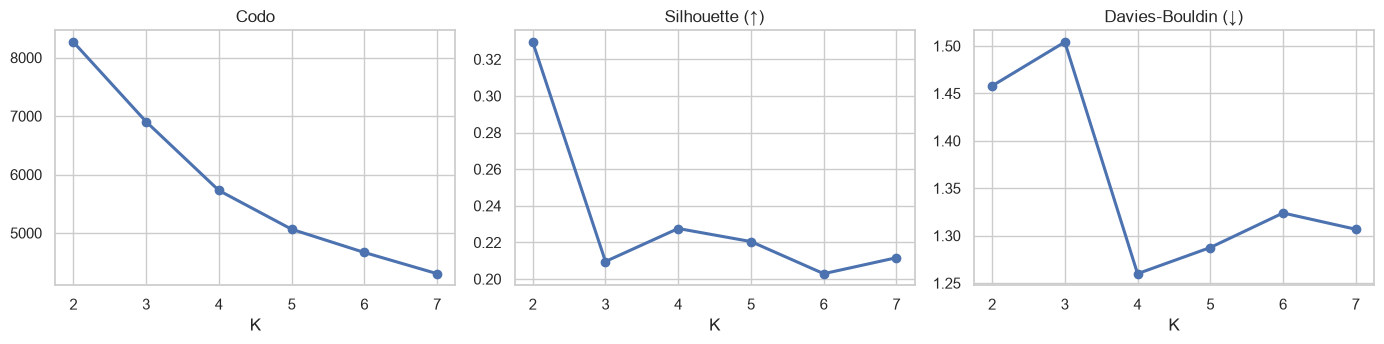

,inercia,silhouette,davies_bouldin,min_cluster_size
K,,,,
2,8266.582,0.329,1.458,315
3,6904.161,0.210,1.504,263
4,5727.407,0.228,1.260,35
5,5064.279,0.220,1.287,34
6,4666.846,0.203,1.324,34
7,4304.039,0.212,1.307,34


In [22]:
# =============================================================================
# BLOQUE 4: BARRIDO DE K (codo, silhouette, Davies-Bouldin, tamaño mínimo)
# =============================================================================
COLS_CLUSTER = ["danceability", "energy", "acousticness", "valence", "tempo", "loudness", "instrumentalness"]

# Sin escalar, la euclídea quedaría dominada por tempo y loudness (Clase 5, bloque 6b)
X_fav = StandardScaler().fit_transform(fav[COLS_CLUSTER])

ks = list(range(2, 8))
filas = []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_fav)
    filas.append({"K": k, "inercia": km.inertia_,
                  "silhouette": silhouette_score(X_fav, km.labels_),
                  "davies_bouldin": davies_bouldin_score(X_fav, km.labels_),
                  "min_cluster_size": np.bincount(km.labels_).min()})
barrido = pd.DataFrame(filas).set_index("K")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (col, titulo) in zip(axes, [("inercia", "Codo"), ("silhouette", "Silhouette (↑)"),
                                    ("davies_bouldin", "Davies-Bouldin (↓)")]):
    ax.plot(ks, barrido[col], marker="o", lw=2.2)
    ax.set_title(titulo)
    ax.set_xlabel("K")
fig.tight_layout()
plt.show()
barrido.round(3)

**Cómo elegimos K.** Como dice la Clase 5, *el K de mayor silhouette es el candidato estadístico, no la decisión*:

- **K = 2** tiene la mayor silhouette (0,33), pero solo separa "fuerte" de "tranquilo": no agrega nada que no supiéramos del EDA.
- **K = 4** tiene el **menor Davies-Bouldin** de todo el barrido (1,26) y la mejor silhouette entre K ≥ 3 (0,23).
- A partir de K = 5 aparecen grupos que se parten sin mejorar las métricas.

Elegimos **K = 4** por tener buenas métricas y ser interpretable. Dos advertencias:

- **La estructura es débil.** Una silhouette de 0,23 indica que los grupos se solapan bastante: es más una forma útil de **partir un continuo** que grupos naturales bien separados. Por eso hablamos de "modos" para describir, no de tipos de canción.
- **El grupo instrumental es en parte un efecto de la escala.** `instrumentalness` vale casi 0 en casi todas las favoritas; al estandarizarla, las pocas canciones con valores altos quedan muy lejos del resto y K-means les arma un grupo propio (35 canciones).

In [23]:
# =============================================================================
# BLOQUE 5: K-MEANS CON K=4 Y NOMBRES "DESPUÉS" (Clase 5, ejercicio 3)
# =============================================================================
K_MODOS = 4
pipe_modos = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=K_MODOS, init="k-means++", n_init=10, random_state=RANDOM_STATE),
)
fav["cluster"] = pipe_modos.fit_predict(fav[COLS_CLUSTER])   # el id de cluster es una etiqueta arbitraria

# Recién ahora, mirando el perfil, le ponemos nombre a cada grupo
medianas = fav.groupby("cluster")[COLS_CLUSTER].median()
instrumental = medianas["instrumentalness"].idxmax()
tranquilo = medianas.drop(instrumental)["energy"].idxmin()
resto = medianas.drop([instrumental, tranquilo])
nombres = {instrumental: "Instrumentales",
           tranquilo: "Tranquilas / acústicas",
           resto["valence"].idxmax(): "Alegres / bailables",
           resto["valence"].idxmin(): "Enérgicas / fuertes"}
ORDEN_MODOS = ["Enérgicas / fuertes", "Alegres / bailables", "Tranquilas / acústicas", "Instrumentales"]
fav["modo_escucha"] = pd.Categorical(fav["cluster"].map(nombres), categories=ORDEN_MODOS)

# Perfil de cada grupo (medianas)
perfil = fav.groupby("modo_escucha", observed=True)[COLS_CLUSTER].median().round(2)
perfil.insert(0, "canciones", fav["modo_escucha"].value_counts())
perfil

,canciones,danceability,energy,acousticness,valence,tempo,loudness,instrumentalness
modo_escucha,,,,,,,,
Enérgicas / fuertes,646,0.46,0.87,0.00,0.38,138.02,-4.73,0.00
Alegres / bailables,584,0.65,0.81,0.03,0.71,115.97,-5.19,0.00
Tranquilas / acústicas,268,0.56,0.48,0.54,0.39,113.41,-8.70,0.00
Instrumentales,35,0.46,0.82,0.01,0.43,118.88,-6.78,0.78


**¿Qué canciones representan a cada grupo?** Las 4 más cercanas al centro de cada grupo son las más "típicas".

In [24]:
# Distancia de cada canción al centroide de su grupo (pipe.transform devuelve distancias a los K centros)
fav["dist_centro"] = pipe_modos.transform(fav[COLS_CLUSTER])[np.arange(len(fav)), fav["cluster"]]

filas = []
for modo in ORDEN_MODOS:
    ejemplos = fav[fav["modo_escucha"] == modo].sort_values("dist_centro").drop_duplicates("track_name").head(4)
    filas.append({"modo": modo, "canciones típicas": " · ".join(ejemplos["track_name"] + " — " + ejemplos["artista"])})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(filas).set_index("modo")

,canciones típicas
modo,
Enérgicas / fuertes,Castle on the Hill — Ed Sheeran · Follow Me Down — The Pretty Reckless · For I Am Death // Life Evermore Pt. 2 — The Pretty Reckless · End Of Me — A Day To Remember
Alegres / bailables,Don't You (Forget About Me) - Remastered 2001 — Simple Minds · La Flor en la Piedra — Ciro y los Persas · Grace Kelly — MIKA · Por Amar al Amor — Miranda!
Tranquilas / acústicas,Ain't No Man Alive Can Handle Me — Dumpster Grooves · Happy Together — The Turtles · Love Song — P!nk · Deudas Del Alma — Lucas Heredia
Instrumentales,"Who Failed the Most — Sonata Arctica · Everyroad - from Hansa Studios, Berlin — Parcels · Heroes - 1999 Remaster — David Bowie · El Arriero - En Vivo — Divididos"


**Variable de control: ¿los modos son géneros?** En la Clase 5 el cultivar del vino quedaba afuera del ajuste y se usaba después como **control**, midiendo el acuerdo con el **ARI**. Hacemos lo mismo con el género de las favoritas: lo resumimos en macro-géneros y comparamos.

In [25]:
# =============================================================================
# BLOQUE 6: CONTROL EXTERNO — MODOS VS. GÉNERO (ARI, Clase 5)
# =============================================================================
def macro_genero(generos):
    """Resume la lista de géneros de Spotify en un macro-género (el primero que coincida)."""
    for clave_genero, nombre in [("metal", "metal"), ("punk", "punk"), ("folk", "folklore"),
                                 ("chamam", "folklore"), ("rock", "rock"), ("pop", "pop")]:
        if clave_genero in generos:
            return nombre
    return "otro"

con_genero = fav["genres"].notna()          # el 31% sin género queda afuera del control
fav.loc[con_genero, "macro_genero"] = fav.loc[con_genero, "genres"].str.lower().map(macro_genero)

cruce_genero = pd.crosstab(fav.loc[con_genero, "macro_genero"], fav.loc[con_genero, "modo_escucha"])
ari_genero = adjusted_rand_score(fav.loc[con_genero, "macro_genero"], fav.loc[con_genero, "cluster"])
print(f"ARI modos de escucha vs. macro-género: {ari_genero:.3f}  (0 = sin acuerdo, 1 = idénticos)")
cruce_genero

ARI modos de escucha vs. macro-género: 0.064  (0 = sin acuerdo, 1 = idénticos)


modo_escucha,Enérgicas / fuertes,Alegres / bailables,Tranquilas / acústicas,Instrumentales
macro_genero,,,,
folklore,6,30,47,0
metal,167,35,14,6
otro,23,55,35,7
pop,6,79,9,0
punk,58,43,1,0
rock,164,169,91,11


Los 2 ejes explican el 57% de la variación (34% + 23%)
                  Componente 1  Componente 2
danceability              0.00          0.70
energy                    0.60         -0.04
acousticness             -0.51          0.12
valence                   0.20          0.62
tempo                     0.20         -0.28
loudness                  0.55         -0.00
instrumentalness         -0.07         -0.17


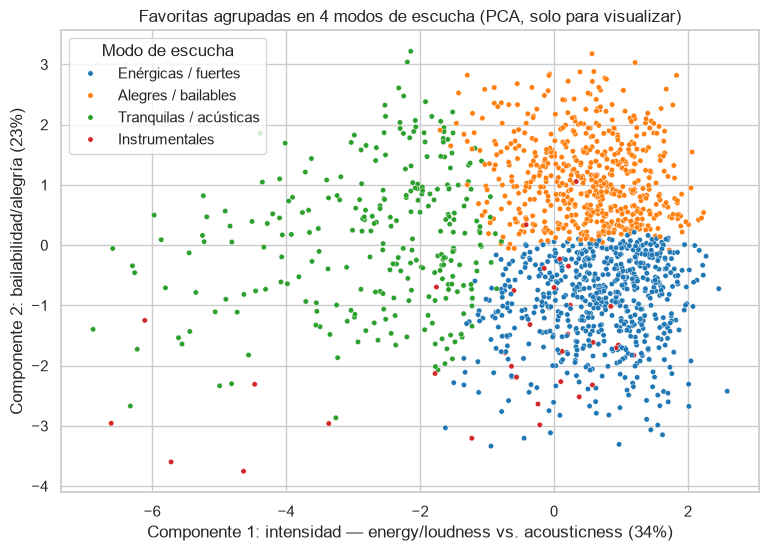

In [26]:
# Proyección en 2D con PCA: SOLO para dibujar (el clustering se hizo en las 7 dimensiones)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(pipe_modos.named_steps["standardscaler"].transform(fav[COLS_CLUSTER]))
var = pca.explained_variance_ratio_

# ¿Qué representa cada eje? Peso de cada variable en cada componente
print(f"Los 2 ejes explican el {var.sum():.0%} de la variación ({var[0]:.0%} + {var[1]:.0%})")
print(pd.DataFrame(pca.components_, columns=COLS_CLUSTER, index=["Componente 1", "Componente 2"]).round(2).T)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=fav["modo_escucha"], hue_order=ORDEN_MODOS,
                palette="tab10", s=15, ax=ax)
ax.set_title("Favoritas agrupadas en 4 modos de escucha (PCA, solo para visualizar)")
ax.set_xlabel(f"Componente 1: intensidad — energy/loudness vs. acousticness ({var[0]:.0%})")
ax.set_ylabel(f"Componente 2: bailabilidad/alegría ({var[1]:.0%})")
ax.legend(title="Modo de escucha")

plt.show()

**Cómo leer estos resultados:**

- **Los grupos son de *sonido*, no de género.** El ARI contra el macro-género es casi 0: los modos de escucha y los géneros prácticamente no coinciden. El rock se reparte entre los cuatro modos, y entre las canciones típicas de "Enérgicas / fuertes" aparece *Castle on the Hill* de Ed Sheeran junto a The Pretty Reckless y A Day To Remember: en energía, volumen y acústica son vecinas. Es la misma limitación que discutimos en la Etapa 5: **las audio features no capturan idioma, cultura ni género.**
- **Los grupos son un resumen, no una verdad.** Con silhouette 0,23 hay muchas canciones en la frontera entre dos modos. Que *Heroes* de Bowie o *El Arriero* en vivo de Divididos aparezcan entre las "típicas" del grupo instrumental muestra que el grupo junta canciones con mucho tramo instrumental, no solo instrumentales puras.
- **El PCA es una simplificación.** Los dos ejes conservan poco más de la mitad de la información, por eso los grupos se ven pegados. El grupo instrumental aparece desparramado porque lo que lo define (`instrumentalness`) casi no pesa en estos dos ejes. **Del mapa no se puede concluir** que dos grupos estén "cerca" o "lejos" en el espacio original.

### ¿Qué observar?

- En los **histogramas**: ¿la distribución es simétrica, sesgada, tiene varios picos? ¿Hay valores extremos (*outliers*)?
- En las **tablas de frecuencia**: ¿las categorías están balanceadas o hay una dominante?
- En la **correlación**: ¿hay pares de variables fuertemente relacionadas? ¿Eso tiene sentido en el dominio del problema?


### ✏️ Su respuesta — Etapa 3

**Hallazgos principales del EDA:**

1. **Las favoritas son más enérgicas y "fuertes".** La mediana de `energy` es 0,80 contra 0,68 del catálogo (el 68% supera 0,7, contra el 47% del catálogo). La de `loudness` es −5,4 dB contra −7,2 dB.
2. **Casi nada acústico ni instrumental.** La mediana de `acousticness` es 0,02 contra 0,19 (el 62% está por debajo de 0,05, contra el 34%). El pico de canciones instrumentales del catálogo (clásica, ambient, etc.) casi no aparece en las favoritas.
3. **Pocas canciones muy "oscuras".** La cola baja de `valence` (< 0,2) casi no está: la mediana es 0,51 contra 0,46. `danceability` es apenas menor (0,55 contra 0,58).
4. **Variables que no distinguen:** `tempo` (122 BPM en ambos), `speechiness`, contenido explícito (8% contra 9%) y modo mayor (62% contra 64%) son casi iguales. Probablemente aporten poco al modelo.
5. **Redundancia:** `energy`–`loudness` tienen correlación 0,74, `energy`–`acousticness` −0,65 y `danceability`–`valence` 0,55. Hay que tenerlo en cuenta al interpretar el modelo.
6. **Cuánto se diferencian (PSI, Clase 8).** Las mayores diferencias están en `acousticness` (PSI 0,53), `loudness` (0,46), `instrumentalness` (0,45) y `energy` (0,32), todas por encima del umbral convencional de 0,25. `tempo` (0,04) y `liveness` (0,02) casi no cambian. Esto anticipa qué features va a usar el modelo.
7. **Gustos variados: 4 modos de escucha (Clase 5).** Dominan el rock argentino (317 canciones), el metal y el rock latino, pero también hay folklore y chamamé. Un K-means sobre las favoritas da 4 modos (K = 4 por tener el menor Davies-Bouldin, 1,26): enérgicas/fuertes (646), alegres/bailables (584), tranquilas/acústicas (268) e instrumentales (35). Agrupan por **sonido**, no por género (ARI 0,06 contra el macro-género), y con silhouette 0,23 son una descripción útil de la variedad, no grupos nítidos. El modelo de la Etapa 4 no usa estos modos, y eso explica parte de la burbuja de filtro de la Etapa 5.
8. **Temporal y texto:** la mayoría de las canciones son de los años 2000 y 2010. El usuario guarda favoritas desde 2014. Hay 322 artistas distintos y el top 10 concentra el 34% de las canciones.

# Etapa 4 — Propuesta de modelo

A partir de lo que vieron, propongan **qué tipo de modelo** se podría construir con este dataset. La pregunta guía es: *¿qué tipo de problema de aprendizaje automático representan estos datos?*

| Si... | Entonces el tipo de modelo es... |
|---|---|
| Hay un **target categórico** (clase/etiqueta) | **Clasificación** |
| Hay un **target numérico continuo** | **Regresión** |
| **No hay target** y se buscan grupos | **Agrupamiento (*clustering*)** |
| Los datos son una **serie temporal** | **Pronóstico (*forecasting*)** |

> **No tienen que entrenar el modelo.** Solo deben **justificar** qué tipo correspondería y qué variable sería el *target* (si lo hubiera).


### ✏️ Su respuesta — Etapa 4

**Tipo de modelo propuesto:** **clasificación binaria**, usada como **recomendador por contenido**. El modelo da un **puntaje** a cada canción del catálogo y se recomiendan las de mayor puntaje. Técnicamente es un problema de aprendizaje **Positive-Unlabeled (PU)**: como los ceros mezclan canciones que no le gustan con canciones que no conoce, el puntaje sirve para **ordenar**, pero no es una probabilidad calibrada de que le guste.

**Variable objetivo:** `es_favorita` (1 = está en las Liked Songs del usuario, 0 = no etiquetada).

**Variables de entrada (features):** las 11 *audio features*: `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `mode` y la duración en escala logarítmica (`log_duracion`). Las columnas excluidas y sus motivos están en el Bloque 3.

**Justificación:**
- El target es **categórico** (le gusta / no), así que corresponde clasificación. No es regresión porque no tenemos una calificación numérica, y no es clustering puro porque sí tenemos etiquetas, aunque solo positivas. El clustering queda como herramienta complementaria para entender los "modos" del usuario.
- El EDA muestra diferencias claras (PSI > 0,25) en `acousticness`, `loudness`, `instrumentalness` y `energy`, así que hay señal para aprender.
- **La sutileza PU:** los ceros no son "no le gusta" sino "no la conoce". Por eso no evaluamos con *accuracy* (un modelo que siempre dijera 0 tendría 94% en entrenamiento), sino con las **métricas de ranking de la Clase 8** sobre favoritas que el modelo no vio: Average Precision, Precision@100 y recall en el top 10%.

**Resultado del prototipo:** ver la *Conclusión del prototipo* al final de esta etapa.


### Prototipo (opcional): ¿funciona la idea?

La consigna no pide entrenar, pero vale la pena comprobar que la propuesta tiene sentido.

**El problema de evaluar sin negativos.** No sabemos qué canciones *no* le gustan al usuario: solo tenemos positivos y "no etiquetadas" (aprendizaje *Positive-Unlabeled*). La solución es usar las favoritas que **ya están** en el catálogo como **"favoritas ocultas"**: entrenamos **sin** ellas y medimos en qué puesto del ranking quedan.

**Alcance: el sistema recomienda *canciones*.** El catálogo incluye *mixes* de DJ de más de una hora, pistas de ruido blanco para dormir (género `sleep`) y fragmentos de pocos segundos. Ninguno es una canción que el usuario agregaría a una playlist, así que los dejamos fuera del universo de candidatos con una **regla de negocio armada aparte** (como la regla de recencia de la Clase 5): duración entre 1 y 10 minutos y género distinto de `sleep`. Esta regla surgió de **mirar las recomendaciones de una primera versión**; al final de la etapa mostramos qué pasa sin ella.

Las particiones quedan así:

| Partición | Contenido | Uso |
|---|---|---|
| **Entrenamiento** | Favoritas que *no* están en el catálogo (positivos) + muestra de 20.000 canciones del universo (no etiquetadas) | Ajustar los modelos (con CV interna) |
| **Evaluación** | El resto del universo, con las favoritas ocultas mezcladas | Medir el ranking con las métricas de la Clase 8 |

Ninguna canción de evaluación participa del entrenamiento. Los **artistas**, en cambio, sí pueden repetirse: puede quedar oculto un tema de Green Day mientras otros de Green Day se usan como positivos. Más abajo medimos cuánto pesa eso.

In [27]:
# =============================================================================
# BLOQUE 7: ALCANCE Y PARTICIÓN ENTRENAMIENTO / EVALUACIÓN
# =============================================================================
# Regla de negocio (no la aprende el modelo): solo canciones de 1 a 10 minutos y sin ruido blanco
DURACION_MIN, DURACION_MAX = 1, 10   # minutos
es_cancion = (catalogo["duration_ms"].between(DURACION_MIN * 60_000, DURACION_MAX * 60_000)
              & (catalogo["track_genre"] != "sleep"))
universo = catalogo[es_cancion]
print(f"Fuera del alcance: {(~es_cancion).sum():,} pistas | universo de candidatos: {len(universo):,}")


def primer_artista(artistas):
    """Primer artista en minúsculas: es el grupo para la validación cruzada."""
    return artistas.fillna("").str.split(r"[;,]").str[0].str.lower().str.strip()


def armar_entrenamiento(seed, candidatos=universo):
    """Positivos = favoritas fuera del catálogo; no etiquetadas = muestra de candidatos sin favoritas.
    Devuelve también el artista de cada fila, para que la CV no reparta un artista entre folds."""
    positivos = fav.loc[~fav["en_catalogo"]]
    no_etiq = candidatos[~candidatos["es_favorita"]].sample(N_NO_ETIQUETADAS, random_state=seed)
    X = pd.concat([positivos[FEATURES], no_etiq[FEATURES]], ignore_index=True)
    y = np.r_[np.ones(len(positivos)), np.zeros(len(no_etiq))].astype(int)
    grupos = pd.concat([primer_artista(positivos["artists"]), primer_artista(no_etiq["artists"])],
                       ignore_index=True).to_numpy()
    return X, y, grupos, no_etiq.index

X_ent, y_ent, g_ent, idx_no_etiq = armar_entrenamiento(RANDOM_STATE)

# Evaluación: universo sin las canciones usadas al entrenar
evaluacion = universo.drop(idx_no_etiq)
X_eval, y_eval = evaluacion[FEATURES], evaluacion["es_favorita"].astype(int).to_numpy()

print(f"Entrenamiento: {len(X_ent):,} filas | positivos: {y_ent.sum():,} ({y_ent.mean():.1%})")
print(f"Evaluación   : {len(X_eval):,} filas | favoritas ocultas: {y_eval.sum():,} (prevalencia {y_eval.mean():.2%})")

Fuera del alcance: 2,290 pistas | universo de candidatos: 87,451
Entrenamiento: 21,189 filas | positivos: 1,189 (5.6%)
Evaluación   : 67,451 filas | favoritas ocultas: 498 (prevalencia 0.74%)


### Modelos candidatos

Como en la Clase 2, todo modelo se compara contra un **baseline**. Todos los modelos con escalado van dentro de un `Pipeline`, así el `StandardScaler` se ajusta solo con los datos de entrenamiento (sin *leakage*).

| Modelo | Idea | Práctica |
|---|---|---|
| `DummyClassifier(strategy="prior")` / azar | Baseline: el Dummy da el mismo puntaje a todo (sirve para la CV); para ordenar, su equivalente es un orden aleatorio | Clase 2 |
| kNN (10 vecinos) | ¿Se parece a *alguna* favorita? Distancia euclídea en el espacio estandarizado | Clases 3 y 5 |
| Regresión logística | Lineal, interpretable por coeficientes | Clases 2 y 3 |
| Random Forest | Ensamble de árboles | Clase 4 |

**Validación cruzada interna.** Primero, `StratifiedGroupKFold(5)` sobre el conjunto de entrenamiento, con `average_precision` y `roc_auc`. Los grupos son los **artistas**: el usuario tiene muchos temas de pocos artistas (el top 10 concentra un tercio de las favoritas), y si un artista queda de los dos lados del split el modelo puede aprender "cómo suena ese artista" y reconocerlo en validación, algo que no pasa al recomendar artistas nuevos. Más abajo mostramos cuánto cambia el resultado si no agrupamos. Ojo: esto mide qué tan bien separa favoritas de **una muestra del catálogo**, que incluye canciones que también le gustarían al usuario. Por eso la evaluación principal es la de las favoritas ocultas.

In [28]:
# =============================================================================
# BLOQUE 8: PIPELINES + VALIDACIÓN CRUZADA ESTRATIFICADA Y AGRUPADA POR ARTISTA (Clases 2 y 4)
# =============================================================================
pipelines = {
    "Dummy (prior)": make_pipeline(DummyClassifier(strategy="prior")),
    "Regresión logística": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                               n_jobs=-1, random_state=RANDOM_STATE)),
}

# Un mismo artista nunca queda de los dos lados del split
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
filas_cv, modelos = {}, {}
for nombre, pipe in pipelines.items():
    res = cross_validate(pipe, X_ent, y_ent, groups=g_ent, cv=folds,
                         scoring=["average_precision", "roc_auc"], return_train_score=True)
    filas_cv[nombre] = {
        "AP val (media)": res["test_average_precision"].mean(),
        "AP val (desvío)": res["test_average_precision"].std(),
        "AP train (media)": res["train_average_precision"].mean(),
        "ROC-AUC val (media)": res["test_roc_auc"].mean(),
        "ROC-AUC val (desvío)": res["test_roc_auc"].std(),
    }
    modelos[nombre] = clone(pipe).fit(X_ent, y_ent)   # clone: el pipeline original queda sin ajustar

resultados_cv = pd.DataFrame(filas_cv).T
resultados_cv.round(3)

,AP val (media),AP val (desvío),AP train (media),ROC-AUC val (media),ROC-AUC val (desvío)
Dummy (prior),0.056,0.000,0.056,0.500,0.000
Regresión logística,0.141,0.030,0.143,0.752,0.027
Random Forest,0.164,0.019,1.000,0.752,0.017


In [29]:
# ¿Qué pasa si no agrupamos por artista? Misma CV, pero con StratifiedKFold común
sin_grupos = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
comparacion_cv = pd.DataFrame({
    nombre: {
        "AP sin agrupar": cross_validate(pipelines[nombre], X_ent, y_ent, cv=sin_grupos,
                                         scoring="average_precision")["test_score"].mean(),
        "AP agrupada por artista": resultados_cv.loc[nombre, "AP val (media)"],
    }
    for nombre in ["Regresión logística", "Random Forest"]
}).T
comparacion_cv["caída"] = comparacion_cv["AP sin agrupar"] - comparacion_cv["AP agrupada por artista"]
comparacion_cv.round(3)

,AP sin agrupar,AP agrupada por artista,caída
Regresión logística,0.143,0.141,0.002
Random Forest,0.257,0.164,0.093


### Evaluación con favoritas ocultas: métricas de ranking (Clase 8)

El modelo no se usa para decir "sí/no", sino para **ordenar** el catálogo. Por eso usamos las métricas de ranking de la Clase 8:

- **Average Precision (AP):** resume la curva Precision-Recall. La referencia del azar es la **prevalencia** (menos del 1%).
- **Precision@100:** de las 100 primeras recomendaciones (lo que el usuario escucharía en una playlist), ¿qué proporción son favoritas ocultas?
- **Recall en el top 10%:** qué proporción de las favoritas ocultas cae en el primer 10% del ranking.
- **Puesto mediano:** dónde queda la favorita oculta "del medio", como fracción del ranking (azar ≈ 0,5).

Las favoritas ocultas son una **cota inferior** de los aciertos: una canción recomendada que no está en favoritos puede gustarle igual al usuario.

In [30]:
# =============================================================================
# BLOQUE 9: MÉTRICAS DE RANKING SOBRE LAS FAVORITAS OCULTAS (Clase 8)
# =============================================================================
def precision_at_k(y_true, scores, k):
    # Proporción de positivos entre los k casos de mayor puntaje
    idx_top = np.argsort(scores)[::-1][:k]
    return y_true[idx_top].mean()


def evaluar_ranking(y_true, scores):
    puesto = pd.Series(scores).rank(pct=True, ascending=False).to_numpy()[y_true == 1]
    return {
        "AP": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        f"Precision@{K_PLAYLIST}": precision_at_k(y_true, scores, K_PLAYLIST),
        "Recall top 10%": (puesto <= 0.10).mean(),
        "Puesto mediano": np.median(puesto),
    }


def knn_puntaje(X_pos, X_cand, k=10):
    """Menos distancia media a las k favoritas más cercanas = más puntaje (Clases 3 y 5)."""
    escalador = StandardScaler().fit(X_ent)
    vecinos = NearestNeighbors(n_neighbors=k).fit(escalador.transform(X_pos))
    distancias, _ = vecinos.kneighbors(escalador.transform(X_cand))
    return -distancias.mean(axis=1)


X_pos = X_ent[y_ent == 1]
puntajes = {
    "Azar": rng.random(len(X_eval)),   # el Dummy da un puntaje constante: para ordenar, el baseline es el azar
    "kNN (10 vecinos)": knn_puntaje(X_pos, X_eval),
    "Regresión logística": modelos["Regresión logística"].predict_proba(X_eval)[:, 1],
    "Random Forest": modelos["Random Forest"].predict_proba(X_eval)[:, 1],
}

resultados = pd.DataFrame({nombre: evaluar_ranking(y_eval, s) for nombre, s in puntajes.items()}).T
print(f"Referencia del azar → AP ≈ prevalencia = {y_eval.mean():.4f}")
resultados.round(4)

Referencia del azar → AP ≈ prevalencia = 0.0074


,AP,ROC-AUC,Precision@100,Recall top 10%,Puesto mediano
Azar,0.0071,0.4967,0.00,0.0763,0.5017
kNN (10 vecinos),0.0215,0.7673,0.00,0.3434,0.1684
Regresión logística,0.0304,0.8107,0.08,0.4357,0.1191
Random Forest,0.0258,0.8022,0.01,0.4418,0.1386


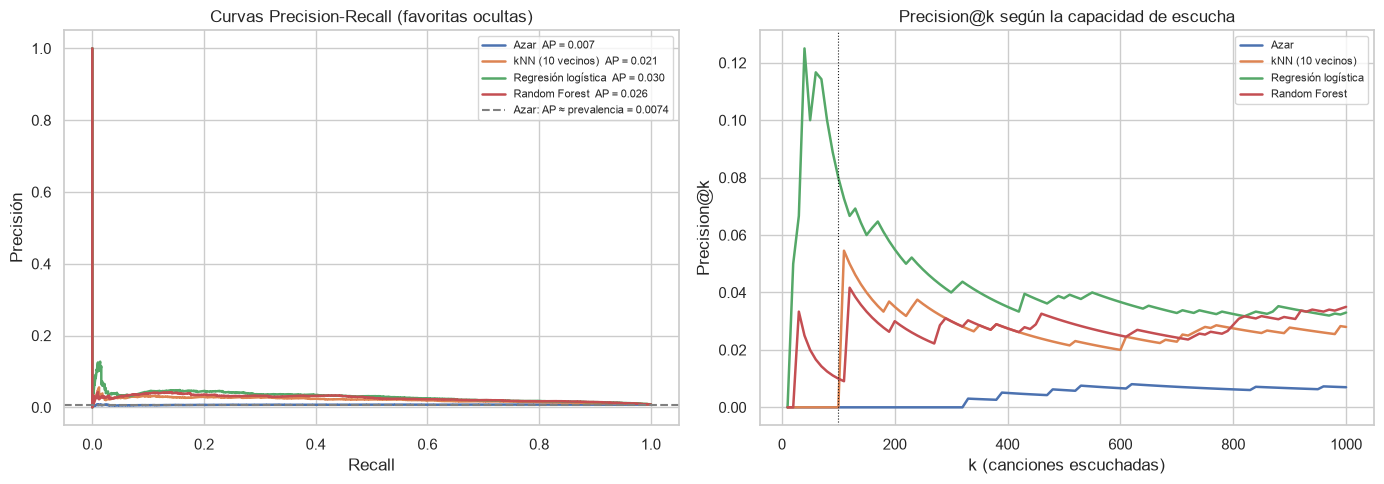

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curvas Precision-Recall (Clase 8)
for nombre, s in puntajes.items():
    prec, rec, _ = precision_recall_curve(y_eval, s)
    axes[0].plot(rec, prec, lw=1.8, label=f"{nombre}  AP = {average_precision_score(y_eval, s):.3f}")
axes[0].axhline(y_eval.mean(), color="gray", ls="--", label=f"Azar: AP ≈ prevalencia = {y_eval.mean():.4f}")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precisión")
axes[0].set_title("Curvas Precision-Recall (favoritas ocultas)")
axes[0].legend(fontsize=8)

# Precision@k según la capacidad de escucha (Clase 8)
ks_cap = np.arange(10, 1001, 10)
for nombre, s in puntajes.items():
    axes[1].plot(ks_cap, [precision_at_k(y_eval, s, k) for k in ks_cap], lw=1.8, label=nombre)
axes[1].axvline(K_PLAYLIST, color="k", lw=0.8, ls=":")
axes[1].set_xlabel("k (canciones escuchadas)")
axes[1].set_ylabel("Precision@k")
axes[1].set_title("Precision@k según la capacidad de escucha")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### ¿Y con artistas que el modelo no vio? (el mismo problema que en la CV)

Las favoritas ocultas son canciones que el modelo no vio, pero **no necesariamente de artistas que no vio**: los positivos de entrenamiento salen de las mismas Liked Songs, así que un tema de Green Day puede quedar oculto mientras otros de Green Day se usan para entrenar. Es exactamente lo que corregimos en la validación cruzada al agrupar por artista.

Separamos las favoritas ocultas en dos subconjuntos según si su (primer) artista aparece entre los positivos de entrenamiento. Las no favoritas son las mismas en los dos casos; solo cambia qué favoritas ocultas se cuentan. Como la prevalencia cambia, cada AP se compara contra la suya.

In [32]:
# =============================================================================
# BLOQUE 9 bis: FAVORITAS OCULTAS DE ARTISTAS NUEVOS VS. CONOCIDOS
# =============================================================================
artistas_ent = set(primer_artista(fav.loc[~fav["en_catalogo"], "artists"]))
artista_eval = primer_artista(evaluacion["artists"])
oculta = y_eval == 1
oculta_conocida = oculta & artista_eval.isin(artistas_ent).to_numpy()
print(f"Favoritas ocultas de artistas que el modelo ya vio al entrenar: {oculta_conocida.sum()} de {oculta.sum()} "
      f"({oculta_conocida.sum() / oculta.sum():.0%})")

# ¿De quién son los aciertos de la logística en el top de la playlist?
top = np.argsort(puntajes["Regresión logística"])[::-1][:K_PLAYLIST]
aciertos = top[oculta[top]]
print(f"Aciertos de la logística en el top {K_PLAYLIST}: {len(aciertos)}, "
      f"de artistas ya vistos: {oculta_conocida[aciertos].sum()} "
      f"({', '.join(artista_eval.iloc[aciertos].value_counts().index)})")

subconjuntos = {"Artistas nuevos": ~oculta_conocida, "Artistas conocidos": ~(oculta & ~oculta_conocida)}
por_artista = pd.DataFrame([
    {"subconjunto": sub, "modelo": nombre, "favoritas ocultas": y_eval[m].sum(), "prevalencia": y_eval[m].mean(),
     **evaluar_ranking(y_eval[m], s[m])}
    for sub, m in subconjuntos.items() for nombre, s in puntajes.items()
    if nombre in ("Regresión logística", "Random Forest")
]).set_index(["subconjunto", "modelo"])

por_artista.round(4)

Favoritas ocultas de artistas que el modelo ya vio al entrenar: 329 de 498 (66%)
Aciertos de la logística en el top 100: 8, de artistas ya vistos: 7 (green day, nightwish, breaking benjamin, avenged sevenfold, pearl jam)


favoritas ocultas  prevalencia  \
subconjunto        modelo                                                
Artistas nuevos    Regresión logística                169       0.0025   
                   Random Forest                      169       0.0025   
Artistas conocidos Regresión logística                329       0.0049   
                   Random Forest                      329       0.0049   

                                            AP  ROC-AUC  Precision@100  \
subconjunto        modelo                                                
Artistas nuevos    Regresión logística  0.0085   0.7848           0.01   
                   Random Forest        0.0070   0.7560           0.00   
Artistas conocidos Regresión logística  0.0235   0.8239           0.07   
                   Random Forest        0.0196   0.8259           0.01   

                                        Recall top 10%  Puesto mediano  
subconjunto        modelo                                               
Artistas nuevos    Regresión logística          0.3964          0.1549  
                   Random Forest                0.3550          0.1921  
Artistas conocidos Regresión logística          0.4620          0.1123  
                   Random Forest                0.4863          0.1069

**Lectura.** Dos de cada tres favoritas ocultas (329 de 498) son de artistas que el modelo ya vio, y **7 de los 8 aciertos de la logística en el top 100 vienen de ahí**. La Precision@100 = 0,08 mide en buena parte que el modelo reconoce más temas de un artista que ya conoce, justo lo que le criticamos al Random Forest en la CV.

Con artistas nuevos, que es el uso que nos interesa (descubrir música), el modelo **sigue teniendo señal**: la logística llega a ROC-AUC 0,78 y a un AP de 3,4 veces la prevalencia, y el 40% de esas favoritas cae en el top 10% del ranking (al azar sería el 10%). Pero la Precision@100 cae a 0,01: en una playlist de 100 canciones, casi ningún acierto *verificable* es de un artista nuevo. Recordemos que es una cota inferior, porque una recomendación que no está en favoritos puede gustarle igual.

La logística es la mejor también con artistas nuevos. El Random Forest empata con artistas conocidos (ROC-AUC 0,83) y pierde con los nuevos (0,76 contra 0,78), algo coherente con lo que vimos en la CV: su ventaja está en reconocer artistas.

### ¿Cuál de los dos modelos elegimos?

**Regresión logística.** Siguiendo la regla de la Clase 8, un modelo más complejo se adopta solo si mejora claramente al más simple, y con las favoritas ocultas el Random Forest no mejora en ninguna métrica:

- **AP:** 0,026 contra 0,030 de la logística.
- **Precision@100** (la métrica operativa: una playlist de 100 canciones): 0,01 contra 0,08.
- **Recall en el top 10%:** prácticamente empatados (0,44 en ambos).
- **Con artistas nuevos** (el uso real), la logística es mejor en AP, ROC-AUC y recall en el top 10%.

No medimos si estas diferencias son estadísticamente significativas, pero no hace falta: si el modelo complejo no mejora, nos quedamos con el más simple, que además es interpretable.

**¿Por qué el Random Forest parecía mejor en la validación cruzada?** No por la brecha *train – val*: en un Random Forest un AP de entrenamiento cercano a 1 es lo normal (cada árbol crece casi hasta memorizar sus datos) y por sí solo no indica sobreajuste. La explicación está en la tabla del Bloque 8. Con `StratifiedKFold` común, el mismo artista queda de los dos lados del split, y el bosque, que es flexible, aprende "cómo suena" cada artista que el usuario tiene muchas veces (Eruca Sativa, Avril Lavigne, Green Day...). Agrupando por artista, su AP cae de 0,26 a 0,16, mientras que la logística casi no cambia (0,14). Una CV agrupada por artista se parece más al uso real, que es recomendar artistas que el modelo no vio, y por eso deja ver la ventaja real del bosque, que es poca. **La validación cruzada tiene que respetar los grupos que hay en los datos.**

Una aclaración honesta: las favoritas ocultas se usan para **elegir** el modelo y también para **reportar** su desempeño, así que las métricas finales pueden ser un poco optimistas. Con solo cuatro candidatos y diferencias chicas el efecto es menor, pero en un sistema real haría falta un tercer conjunto que no se mire hasta el final.


### ¿Qué aprendió el modelo?

- **Coeficientes** de la regresión logística, sobre features estandarizadas (Clases 2 y 3).
- **Permutation importance** (Clase 4): cuánto cae el AP al desordenar cada feature. No depende del signo de los coeficientes y se calcula sobre la partición de **evaluación** (favoritas ocultas + 10.000 no favoritas), no sobre la de entrenamiento.

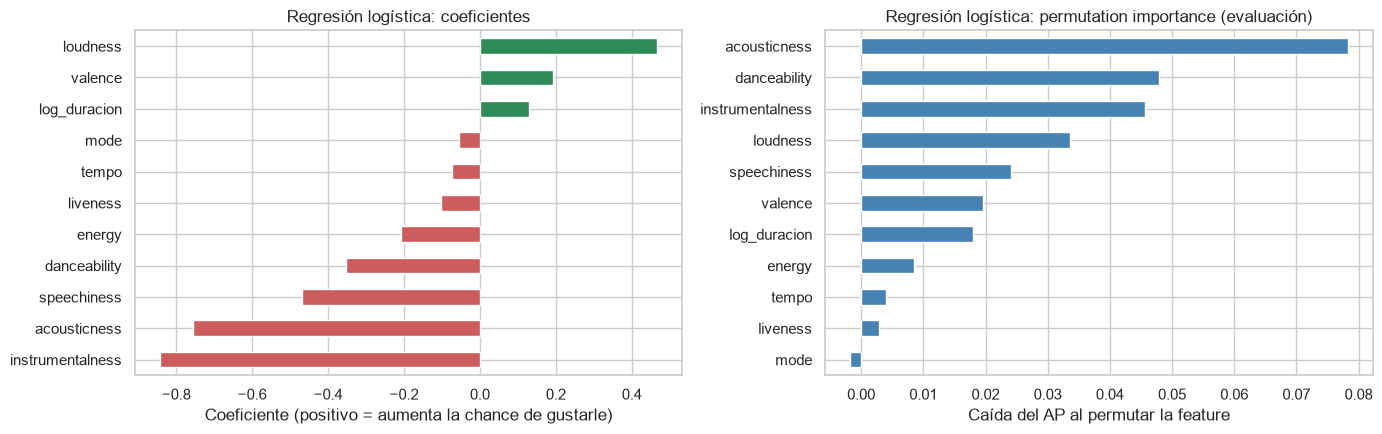

In [33]:
# =============================================================================
# BLOQUE 10: INTERPRETABILIDAD — COEFICIENTES Y PERMUTATION IMPORTANCE
# =============================================================================
logreg = modelos["Regresión logística"].named_steps["logisticregression"]
coefs = pd.Series(logreg.coef_[0], index=FEATURES).sort_values()

# Muestra de evaluación para que la permutación sea rápida: todas las ocultas + 10.000 no favoritas
muestra = pd.concat([evaluacion[evaluacion["es_favorita"]],
                     evaluacion[~evaluacion["es_favorita"]].sample(10_000, random_state=RANDOM_STATE)])
perm = permutation_importance(
    modelos["Regresión logística"], muestra[FEATURES], muestra["es_favorita"].astype(int),
    scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importancias = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
coefs.plot.barh(ax=axes[0], color=np.where(coefs > 0, "seagreen", "indianred"))
axes[0].set_title("Regresión logística: coeficientes")
axes[0].set_xlabel("Coeficiente (positivo = aumenta la chance de gustarle)")
importancias.plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Regresión logística: permutation importance (evaluación)")
axes[1].set_xlabel("Caída del AP al permutar la feature")
fig.tight_layout()
plt.show()

**Cuidado al leer los coeficientes:** `energy` sale *negativo* aunque el EDA mostró que las favoritas tienen **más** energía. No es una contradicción: `energy` y `loudness` están muy correlacionadas (0,74 en la matriz de la sección 3.d), y el modelo "le da el crédito" a `loudness`. Con variables correlacionadas, el signo de un coeficiente aislado no se puede interpretar como el efecto de esa variable sola. La *permutation importance* no depende del signo: la feature más importante es `acousticness`, seguida de `danceability`, `instrumentalness` y `loudness`. Salvo `danceability`, son las de mayor PSI en el EDA: lo que más distingue a las favoritas es lo que más usa el modelo.

### Recomendaciones para el usuario

Reentrenamos el modelo elegido con **todas** las favoritas y rankeamos el universo de candidatos, excluyendo las que el usuario ya tiene y las versiones repetidas. El top 100 queda guardado en `recomendaciones.csv`.

In [34]:
# =============================================================================
# BLOQUE 11: MODELO FINAL Y RECOMENDACIONES
# =============================================================================
def recomendar(modelo, candidatos=universo, n=None):
    """Rankea los candidatos (sin favoritas ni versiones repetidas) según un modelo ya ajustado."""
    candidatos = candidatos[~candidatos["es_favorita"]].copy()
    candidatos["puntaje"] = modelo.predict_proba(candidatos[FEATURES])[:, 1]
    candidatos["duracion_min"] = candidatos["duration_ms"] / 60000
    return candidatos.sort_values("puntaje", ascending=False).drop_duplicates("clave").head(n)


X_final = pd.concat([fav[FEATURES], X_ent[y_ent == 0]], ignore_index=True)
y_final = np.r_[np.ones(len(fav)), np.zeros((y_ent == 0).sum())].astype(int)
modelo_final = clone(pipelines["Regresión logística"]).fit(X_final, y_final)

recomendaciones = recomendar(modelo_final)
top100 = recomendaciones.head(100)[["track_name", "artists", "track_genre", "track_id", "puntaje"]]
top100.to_csv("recomendaciones.csv", index=False)

recomendaciones[["track_name", "artists", "track_genre", "duracion_min", "puntaje"]].head(20).round(3)

,track_name,artists,track_genre,duracion_min,puntaje
54387,銀河鉄道の夜,GING NANG BOYZ,j-rock,7.049,0.918
21578,Global Warming,Gojira,death-metal,7.846,0.901
38871,Pedro Zé - Ao Vivo,Novo Som;Catedral,groove,7.595,0.891
5610,Quintessence,Darkthrone,black-metal,7.615,0.885
44334,En Este Viaje,Almafuerte,heavy-metal,4.719,0.879
54366,蛍の光,Creep Hyp,j-rock,3.199,0.879
50413,In Dreams,Kittie,industrial,3.263,0.879
36835,One Cold Day,Lacuna Coil,goth,6.162,0.878
25740,No Tomorrow,Camo & Krooked;Mefjus;Sophie Lindinger,drum-and-bass,4.526,0.878
18744,Caught Up In You,38 Special,country,4.636,0.875


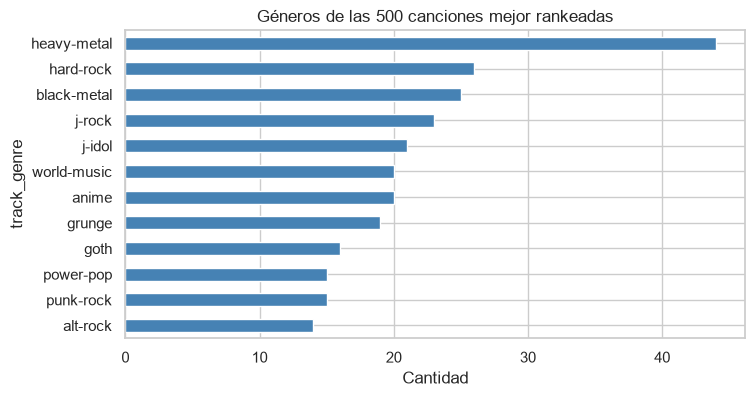

Duración mediana → favoritas: 3.80 min | universo: 3.57 min | top 100: 4.87 min
Más de 6 minutos → favoritas: 3% | universo: 7% | top 100: 30%


In [35]:
# ¿De qué géneros son las 500 mejores recomendaciones?
fig, ax = plt.subplots()
recomendaciones.head(500)["track_genre"].value_counts().head(12).plot.barh(color="steelblue", ax=ax)
ax.invert_yaxis()
ax.set_title("Géneros de las 500 canciones mejor rankeadas")
ax.set_xlabel("Cantidad")
plt.show()

# Control: ¿el modelo sigue empujando hacia las pistas largas dentro de la ventana de 1 a 10 minutos?
top_100 = recomendaciones.head(100)
print(f"Duración mediana → favoritas: {fav['duration_ms'].median() / 60000:.2f} min | "
      f"universo: {universo['duration_ms'].median() / 60000:.2f} min | top 100: {top_100['duracion_min'].median():.2f} min")
print(f"Más de 6 minutos → favoritas: {(fav['duration_ms'] > 360_000).mean():.0%} | "
      f"universo: {(universo['duration_ms'] > 360_000).mean():.0%} | top 100: {(top_100['duracion_min'] > 6).mean():.0%}")

### ¿Qué pasa sin la regla de alcance?

Para justificar la regla, entrenamos la misma regresión logística sobre el **catálogo completo** y miramos su top:

In [36]:
X_sin, y_sin, _, _ = armar_entrenamiento(RANDOM_STATE, candidatos=catalogo)
modelo_sin_regla = clone(pipelines["Regresión logística"]).fit(X_sin, y_sin)
recomendar(modelo_sin_regla, candidatos=catalogo, n=8)[
    ["track_name", "artists", "track_genre", "duracion_min", "puntaje"]].round(2)

,track_name,artists,track_genre,duracion_min,puntaje
54437,東京,GING NANG BOYZ,j-rock,10.30,0.91
54387,銀河鉄道の夜,GING NANG BOYZ,j-rock,7.05,0.91
80512,Pure White Noise - Loopable with No Fade,Sleep Baby Sleep;Relaxation;White Noise Meditation;Spa Relaxation & Spa;Rest & Relax;Deep Sleep,sleep,1.23,0.90
80732,"White Noise - Loopable, No Fade",White Noise Sleep Sounds;Static White Noise Sounds;Real White Noise,sleep,2.37,0.90
21578,Global Warming,Gojira,death-metal,7.85,0.89
30689,God Called In Sick Today,AFI,emo,13.53,0.88
5610,Quintessence,Darkthrone,black-metal,7.62,0.88
38871,Pedro Zé - Ao Vivo,Novo Som;Catedral,groove,7.60,0.88


**Sin la regla, el top se llena de pistas que no son canciones.** Con la duración en escala lineal (una versión anterior de este notebook), la regresión logística concluía *cuanto más larga, mejor* y el top eran *mixes* de DJ de una hora: el modelo **extrapolaba** a duraciones que nunca vio al entrenar. Pasar la duración a **escala log** saca los mixes del top, pero quedan dos problemas que la escala no resuelve:

- **Ruido blanco**: pistas `sleep` que no tienen nada acústico ni vocal y caen del lado "favorito" del modelo en casi todas las features.
- **Sigue la preferencia por lo largo**: temas de 10 a 13 minutos. Incluso dentro de la ventana de 1 a 10 minutos, el top 100 tiene una mediana de 4,9 minutos contra 3,8 de las favoritas, y un 30% supera los 6 minutos contra el 3% de las favoritas (ver el control debajo del gráfico de géneros).

Ninguno de los dos problemas se nota en las métricas. La AP sí penaliza cada pista no favorita que queda por encima de una favorita oculta, pero **penaliza igual a un tema de ruido blanco que a una canción que al usuario podría gustarle**: no distingue un error grave de una recomendación razonable. Y como son pocas pistas (unas 2.300 de 87.000), su efecto en la AP es chico.

**¿Por qué pasa?** Una regresión logística es **monótona** en cada feature: no busca canciones *parecidas* a las favoritas sino las más **extremas** en la dirección de las favoritas (más fuertes, menos acústicas, menos habladas, más largas). Por eso el top tiene medianas más extremas que las propias favoritas. Las soluciones de fondo serían un modelo que capture "parecido" (kNN, o la logística con términos no lineales) o recomendar por modo de escucha. En este prototipo nos quedamos con la logística, porque es la mejor en las métricas, más la regla de alcance.

La lección: **una métrica buena no alcanza; hay que mirar qué recomienda el modelo.**


### Conclusión del prototipo

- La **regresión logística** es la mejor: AP 0,030 (4 veces la prevalencia) y **Precision@100 = 0,08**, pero 7 de esos 8 aciertos son de artistas que el modelo ya vio al entrenar. Con **artistas nuevos**, que es el uso real, la señal se mantiene (ROC-AUC 0,78 y 40% de las favoritas ocultas en el top 10%, contra 10% al azar), aunque la Precision@100 baja a 0,01.
- **La validación cruzada tiene que agrupar por artista:** sin agrupar, el Random Forest parecía mucho mejor (AP 0,26 contra 0,14); agrupando, su ventaja casi desaparece, y con las favoritas ocultas queda por debajo de la logística.
- **Una métrica buena no alcanza:** con la duración lineal el top eran *mixes* de una hora, y sin la regla de alcance aparece ruido blanco. Hay que mirar qué recomienda el modelo.

# Etapa 5 — Uso previsto

Por último, pongan el modelo en contexto. Un modelo no se construye en el vacío: sirve para **ayudar a tomar una decisión**.


### ✏️ Su respuesta — Etapa 5

**¿Para qué se usaría el modelo?** Para **ordenar un catálogo enorme** y sugerir canciones que el usuario no conoce con alta probabilidad de gustarle. Por ejemplo, armar cada semana una playlist de descubrimiento con las 30 primeras del ranking.

**¿Quién lo usaría?** En primer lugar, un oyente individual, como el integrante cuyas favoritas usamos. A mayor escala:
- Una **plataforma de streaming o radio online** que quiere personalizar playlists.
- Un **sello o artista** que lanza un tema nuevo y quiere saber a qué oyentes ofrecérselo. Un tema recién salido no tiene historial de reproducciones (el problema de *cold start*), y ahí un modelo basado en cómo suena la canción sirve más que uno basado en qué escuchan otros usuarios.

**¿Qué decisión ayudaría a tomar?** **Qué canciones escuchar o incluir en una playlist.** De 89.000 canciones, un oyente solo va a escuchar unas decenas. Con artistas que el modelo nunca vio, ~40% de las favoritas ocultas cae en el top 10% del ranking (al azar sería el 10%), así que revisar ese top es mucho más eficiente que explorar al azar. Las cifras de la Etapa 4 que incluyen artistas conocidos (8 favoritas en las primeras 100) son más optimistas: 7 de esos 8 aciertos son de artistas que ya estaban en el entrenamiento. El costo de un error es bajo: si una recomendación no le gusta, la saltea.

**Riesgos o consideraciones éticas:**
- **Burbuja de filtro:** el modelo recomienda más de lo mismo, y además *más extremo* (más fuerte, menos acústico y más largo que las propias favoritas), porque una regresión logística ordena todo según una sola dirección. Los modos minoritarios del usuario, como el folklore o las canciones tranquilas, quedan opacados. Una solución sería recomendar por modo de escucha o mezclar algo de exploración al azar.
- **Las features no capturan idioma, letra ni cultura:** recomienda rock japonés o hardcore brasileño porque *suenan* parecido, pero que le gusten al usuario también depende del idioma y del contexto.
- **Sesgo del catálogo:** está balanceado artificialmente, llega hasta ~2022 y tiene poco rock argentino y folklore, que son justamente los géneros principales del usuario. El modelo solo puede recomendar lo que hay en el catálogo.
- **Los gustos cambian:** hay favoritas desde 2014 y una guardada hace 10 años pesa igual que una de ayer. Se podría ponderar por `added_at`.
- **Monitoreo (Clase 8):** si el sistema se usara de verdad, convendría calcular periódicamente el **PSI** entre las favoritas viejas y las recientes. Un PSI alto indicaría que los gustos cambiaron y que conviene reentrenar.
- **Privacidad:** el export original de Exportify contiene el ID de la cuenta de Spotify (`Added By`) y la fecha y hora exactas en que se guardó cada canción. En la versión compartida del CSV quitamos el ID y dejamos solo la fecha, y el notebook descarta el ID al cargar por si se usa otro export. Aun así, las favoritas revelan gustos personales: no deberían publicarse. En un sistema real haría falta consentimiento del usuario y la posibilidad de borrar sus datos.

# Cierre y entrega

Antes de entregar, verifiquen que:

- [x] Eligieron un dataset y lo cargaron correctamente (Etapa 1).
- [x] Identificaron y clasificaron los tipos de datos (Etapa 2).
- [x] Ejecutaron el EDA con las herramientas adecuadas al tipo de datos (Etapa 3).
- [x] Propusieron y justificaron un tipo de modelo (Etapa 4).
- [x] Explicaron el uso previsto y sus consideraciones (Etapa 5).
- [x] **Todas las celdas están ejecutadas** y sus salidas son visibles.

**Para entregar:** `Archivo → Descargar → Descargar .ipynb`, o compartan el enlace de Colab con permiso de lectura.

---

*Fundamentos de Aprendizaje Automático · 2026 · Universidad Austral*
